# Titanic — Prédire la survie des passagers

Classification binaire sur le dataset Titanic de Kaggle (891 passagers) : à partir de la classe, du sexe, de l'âge, de la famille à bord, du prix du billet, du port d'embarquement et de la présence d'une cabine, le modèle prédit si un passager a survécu.

**Démarche :** pipeline scikit-learn (imputation + one-hot encoding) → forêt aléatoire et régression logistique → réglage des hyperparamètres (RandomizedSearchCV puis GridSearchCV) → évaluation sur un jeu de test mis de côté → analyse des erreurs et du seuil de décision.

Les données (`train.csv`) se téléchargent sur [Kaggle](https://www.kaggle.com/competitions/titanic/data) et se placent dans le dossier `data/`.

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

titanic_file = pd.read_csv("data/train.csv")

titanic_file["HasCabin"] = titanic_file["Cabin"].notna().astype(int)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "HasCabin"]
X = titanic_file[features]
y = titanic_file["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_features = ["Age", "Fare"]
cat_features = ["Sex", "Embarked"]
other_features = ["Pclass", "SibSp", "Parch", "HasCabin"]

num_transformer = SimpleImputer(strategy="median")

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features),
    ("other", "passthrough", other_features),
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42)),
])

model.fit(X_train, y_train)
model.score(X_test, y_test)

0.8100558659217877

In [3]:
y_train.mean()

np.float64(0.38342696629213485)

In [4]:
y_test.mean()

np.float64(0.3854748603351955)

In [5]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500, 700],
    "classifier__max_depth": [None, 5, 10, 15, 20, 30],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__max_features": ["sqrt", "log2", None],
}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    verbose=2,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("RandomizedSearchCV best parameters:")
print(random_search.best_params_)

print("RandomizedSearchCV best CV accuracy:")
print(random_search.best_score_)

best_params = random_search.best_params_

param_grid = {
    "classifier__n_estimators": [
        max(50, best_params["classifier__n_estimators"] - 100),
        best_params["classifier__n_estimators"],
        best_params["classifier__n_estimators"] + 100
    ],

    "classifier__max_depth": (
        [None, 5, 10, 15, 20]
        if best_params["classifier__max_depth"] is None
        else sorted(set([
            max(2, best_params["classifier__max_depth"] - 5),
            best_params["classifier__max_depth"],
            best_params["classifier__max_depth"] + 5
        ]))
    ),

    "classifier__min_samples_split": sorted(set([
        max(2, best_params["classifier__min_samples_split"] - 2),
        best_params["classifier__min_samples_split"],
        best_params["classifier__min_samples_split"] + 2
    ])),

    "classifier__min_samples_leaf": sorted(set([
        max(1, best_params["classifier__min_samples_leaf"] - 1),
        best_params["classifier__min_samples_leaf"],
        best_params["classifier__min_samples_leaf"] + 1
    ])),

    "classifier__max_features": [
        best_params["classifier__max_features"]
    ]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("GridSearchCV best parameters:")
print(grid_search.best_params_)

print("GridSearchCV best CV accuracy:")
print(grid_search.best_score_)

best_model = grid_search.best_estimator_

test_accuracy = best_model.score(X_test, y_test)

print("Final Test Accuracy:", test_accuracy)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
RandomizedSearchCV best parameters:
{'classifier__n_estimators': 700, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': None, 'classifier__max_depth': 10}
RandomizedSearchCV best CV accuracy:
0.8315473259135231
Fitting 10 folds for each of 54 candidates, totalling 540 fits
GridSearchCV best parameters:
{'classifier__max_depth': 10, 'classifier__max_features': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 700}
GridSearchCV best CV accuracy:
0.834330985915493
Final Test Accuracy: 0.7597765363128491


In [6]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X_train, y_train, cv=10, scoring="accuracy")
scores.mean()

np.float64(0.8076486697965573)

In [8]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

titanic_file = pd.read_csv("data/train.csv")

titanic_file["HasCabin"] = titanic_file["Cabin"].notna().astype(int)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "HasCabin"]
X = titanic_file[features]
y = titanic_file["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_features = ["Age", "Fare"]
cat_features = ["Sex", "Embarked"]
other_features = ["Pclass", "SibSp", "Parch", "HasCabin"]

num_transformer = SimpleImputer(strategy="median")

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features),
    ("other", "passthrough", other_features),
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression Accuracy:", logistic_model.score(X_test, y_test))

Logistic Regression Accuracy: 0.8044692737430168


In [9]:
print("Random Forest:", best_model.score(X_test, y_test))
print("Logistic Regression:", logistic_model.score(X_test, y_test))

Random Forest: 0.7597765363128491
Logistic Regression: 0.8044692737430168


In [11]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

param_distributions = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"],
    "classifier__class_weight": [None, "balanced"]
}

random_search_log = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=param_distributions,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    verbose=2,
    n_jobs=-1
)

random_search_log.fit(X_train, y_train)

print("RandomizedSearchCV best parameters:")
print(random_search_log.best_params_)

print("RandomizedSearchCV best CV accuracy:")
print(random_search_log.best_score_)

best_params = random_search_log.best_params_

best_C = best_params["classifier__C"]

param_grid = {
    "classifier__C": [
        best_C / 10,
        best_C,
        best_C * 10
    ],
    "classifier__solver": [
        best_params["classifier__solver"]
    ],
    "classifier__class_weight": [
        best_params["classifier__class_weight"]
    ]
}

grid_search_log = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    verbose=2,
    n_jobs=-1
)

grid_search_log.fit(X_train, y_train)

print("GridSearchCV best parameters:")
print(grid_search_log.best_params_)

print("GridSearchCV best CV accuracy:")
print(grid_search_log.best_score_)

best_logistic_model = grid_search_log.best_estimator_

test_accuracy_log = best_logistic_model.score(X_test, y_test)

print("Final Logistic Regression Test Accuracy:", test_accuracy_log)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
RandomizedSearchCV best parameters:
{'classifier__solver': 'lbfgs', 'classifier__class_weight': None, 'classifier__C': 0.1}
RandomizedSearchCV best CV accuracy:
0.7964247020585048
Fitting 10 folds for each of 3 candidates, totalling 30 fits
GridSearchCV best parameters:
{'classifier__C': 1.0, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
GridSearchCV best CV accuracy:
0.7949139280125196
Final Logistic Regression Test Accuracy: 0.8044692737430168


              precision    recall  f1-score   support

           0       0.78      0.85      0.81       110
           1       0.72      0.62      0.67        69

    accuracy                           0.76       179
   macro avg       0.75      0.73      0.74       179
weighted avg       0.76      0.76      0.76       179



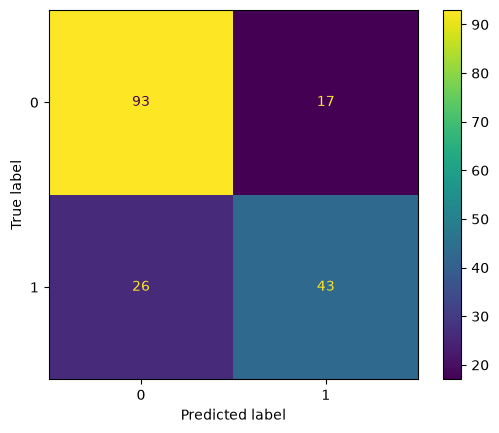

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
print(classification_report(y_test, best_model.predict(X_test)))


              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



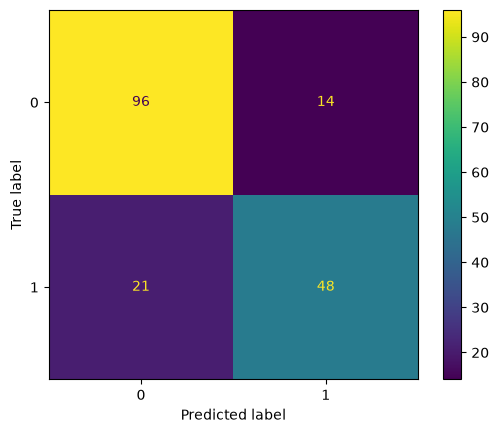

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_estimator(
    best_logistic_model,
    X_test,
    y_test
)

print(classification_report(
    y_test,
    best_logistic_model.predict(X_test)
))


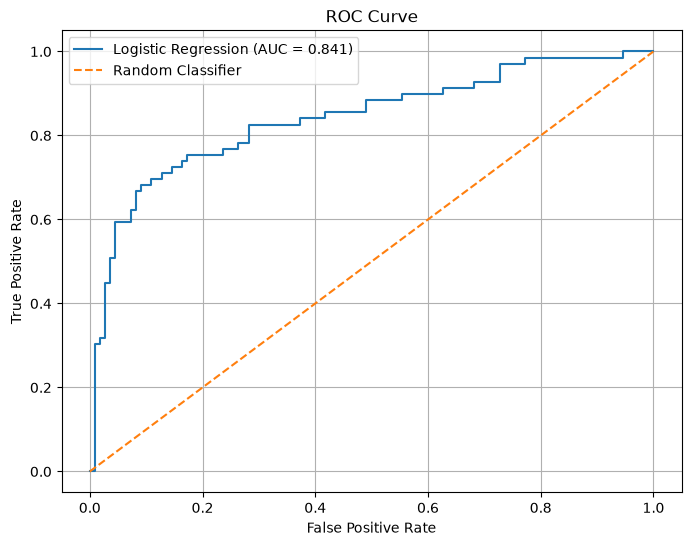

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_proba = best_logistic_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba)

auc_score = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()

plt.show()

In [15]:
y_proba = best_logistic_model.predict_proba(X_test)[:, 1]

In [16]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

y_proba = best_logistic_model.predict_proba(X_test)[:, 1]

results = []

for threshold in thresholds:

    y_pred = (y_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

   Threshold  Accuracy  Precision  Recall  F1-score
0        0.2     0.715      0.594   0.826     0.691
1        0.3     0.749      0.640   0.797     0.710
2        0.4     0.788      0.712   0.754     0.732
3        0.5     0.804      0.774   0.696     0.733
4        0.6     0.799      0.837   0.594     0.695
5        0.7     0.788      0.897   0.507     0.648
6        0.8     0.726      0.955   0.304     0.462


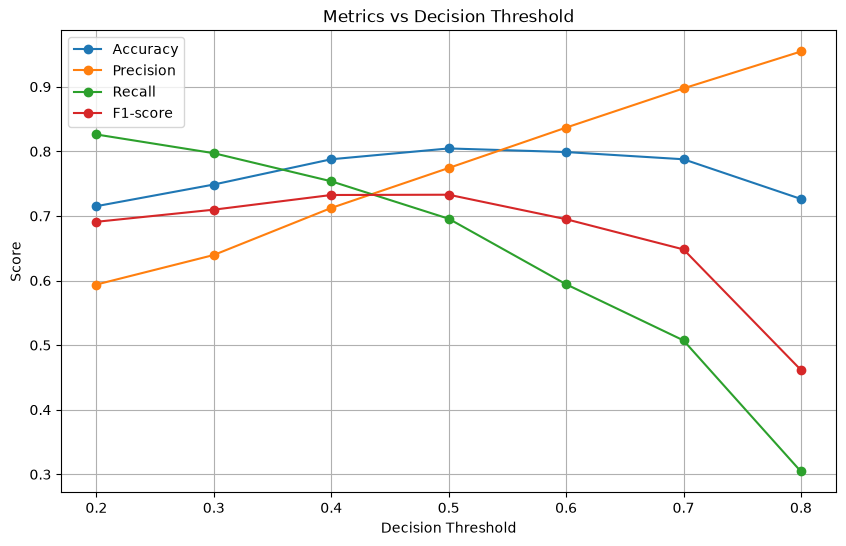

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(results_df["Threshold"], results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(results_df["Threshold"], results_df["Precision"], marker="o", label="Precision")
plt.plot(results_df["Threshold"], results_df["Recall"], marker="o", label="Recall")
plt.plot(results_df["Threshold"], results_df["F1-score"], marker="o", label="F1-score")

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Metrics vs Decision Threshold")

plt.xticks(thresholds)
plt.legend()
plt.grid()
plt.show()


## Conclusion

### Résultats
| Modèle | Validation croisée (10 plis) | Test (179 passagers) |
|---|---|---|
| Référence « toujours mort » | — | 61,5 % |
| Forêt aléatoire par défaut | 80,8 % | 81,0 % |
| Forêt aléatoire réglée | 83,4 % | 76,0 % |
| Régression logistique réglée | 79,5 % | 80,4 % |

### Choix du modèle
- Tous les modèles dépassent nettement la référence (61,5 %) et se situent autour de 80 %.
- Modèle retenu, selon la validation croisée : la forêt aléatoire réglée (83,4 %). Son résultat final sur le test est de 76,0 %.
- L'écart de 7 points entre validation croisée et test montre que le réglage était optimiste : le meilleur score parmi 84 combinaisons surestime le vrai niveau du modèle.
- Sur le test, la régression logistique obtient 80,4 %. Mais avec 179 passagers (un passager = 0,56 point), cet écart reste dans la marge d'incertitude. Le choix n'est pas modifié d'après le test.

### Analyse des erreurs
- Les deux modèles font le même type d'erreur : ils ratent surtout des survivants.
  - Forêt aléatoire : 26 survivants ratés sur 69 (rappel de 0,62 sur la classe 1).
  - Régression logistique : 21 survivants ratés sur 69 (rappel de 0,70).
- Les modèles penchent vers « mort » quand ils hésitent, car 62 % des passagers sont morts.
- Deux modèles très différents se trompent de la même façon : la limite vient surtout des features, pas du choix du modèle.

### Ce que j'ai appris
- On compare et on choisit les modèles avec la validation croisée, jamais avec le test.
- L'accuracy seule cache le type d'erreurs : la matrice de confusion montre que le modèle ne retrouve que 62 % des survivants.
- Sur un petit dataset, des écarts de quelques points ne sont pas fiables.

### Pour aller plus loin
- Extraire le titre du nom (Mr, Mrs, Miss, Master), très lié à l'âge et au sexe.
- Créer une feature FamilySize = SibSp + Parch + 1.
- Comparer ces nouvelles features en validation croisée, puis tester une seule fois le modèle final.